# KV-cache pruning benchmark sweep

Runs on a Colab T4, either in the browser (Runtime > Change runtime type > T4 GPU)
or from VS Code with the Google Colab extension (Select Kernel > Colab >
New Colab Server > GPU > T4 > Python 3).

Clones (or updates) the repo on the Colab machine, installs deps, runs the
baseline-vs-pruned sweep for each model, then builds the figures and summary.


In [ ]:
!nvidia-smi


In [21]:
import os
REPO = "/content/llm-inference-pruning-benchmarks"
if not os.path.isdir(REPO):
    !git clone https://github.com/abdullahforecasts/llm-inference-pruning-benchmarks.git {REPO}
%cd {REPO}
!git pull
!git log --oneline -1
!pip install -q -r requirements.txt


/content/llm-inference-pruning-benchmarks
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 3 (delta 2), reused 3 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 833 bytes | 833.00 KiB/s, done.
From https://github.com/abdullahforecasts/llm-inference-pruning-benchmarks
   f385464..a7a642b  main       -> origin/main
Updating f385464..a7a642b
Fast-forward
 visualize.py | 26 ++++++++++++++++++++++++--
 1 file changed, 24 insertions(+), 2 deletions(-)
a7a642b (HEAD -> main, origin/main, origin/HEAD) visualize: read CSVs with mixed old/new columns and OOM rows


Llama models are gated on Hugging Face: run the login cell once per server.


In [ ]:
from huggingface_hub import login
login()


## Run the sweep

`RUN` names the results folder. Each setting gets 1 warm-up run and 3 timed
repeats (mean and std go into the CSV). The pruned run prefills in 512-token
chunks and evicts after every chunk; the baseline prefills the whole prompt at
once and keeps the full cache.

Main sweep: importance-based eviction, window 512.

- batch 1: the baseline prefills the whole prompt in one pass. On a T4 that
  runs out of memory for long prompts; the run is recorded as `oom` in the CSV
  and the sweep continues.
- batch 8: the baseline also prefills in 512-token chunks
  (`--baseline-prefill-chunk 512`) but keeps the full cache, so both runs fit
  and the comparison isolates the effect of the bounded cache.

Results are appended to the CSV after every prompt length, and `--resume`
skips settings that are already in it, so an interrupted cell can simply be
run again.


In [11]:
RUN = "v2_t4"
OUT = f"results/{RUN}/benchmark.csv"
COMMON = "--max-new-tokens 128 --window-size 512 --sink-tokens 4 --prefill-chunk 512 --warmup 1 --repeats 3 --device cuda --resume"


In [12]:
!python benchmark.py --model qwen2.5-0.5b --batch-size 1 --seq-lens 1024 2048 4096 8192 --mode importance {COMMON} --out {OUT}


Loading weights: 100% 290/290 [00:03<00:00, 75.45it/s]
seq_len=1024 bs=1 | already in results/v2_t4/benchmark.csv, skipping
seq_len=2048 bs=1 | already in results/v2_t4/benchmark.csv, skipping
seq_len=4096 bs=1 | already in results/v2_t4/benchmark.csv, skipping
seq_len=8192 bs=1 | already in results/v2_t4/benchmark.csv, skipping
results appended to results/v2_t4/benchmark.csv


In [13]:
!python benchmark.py --model llama3.2-1b --batch-size 1 --seq-lens 1024 2048 4096 8192 --mode importance {COMMON} --out {OUT}


Loading weights: 100% 146/146 [00:02<00:00, 70.97it/s]
seq_len=1024 bs=1 | already in results/v2_t4/benchmark.csv, skipping
seq_len=2048 bs=1 | baseline tok/s=43.8 peak=3883MB kv=71.3MB | pruned tok/s=35.4 peak=2606MB kv=17.7MB evictions=6
seq_len=4096 bs=1 | baseline tok/s=32.2 peak=7734MB kv=138.4MB | pruned tok/s=35.2 peak=2606MB kv=17.7MB evictions=10
seq_len=8192 bs=1 | baseline OOM | pruned tok/s=35.4 peak=2606MB kv=17.7MB evictions=18
results appended to results/v2_t4/benchmark.csv


In [14]:
!python benchmark.py --model qwen2.5-0.5b --batch-size 8 --seq-lens 2048 4096 8192 --mode importance --baseline-prefill-chunk 512 {COMMON} --out {OUT}


Loading weights: 100% 290/290 [00:00<00:00, 355.33it/s]
seq_len=2048 bs=8 | baseline tok/s=153.4 peak=1430MB kv=213.8MB | pruned tok/s=193.5 peak=1433MB kv=53.1MB evictions=6
seq_len=4096 bs=8 | baseline tok/s=81.9 peak=1826MB kv=415.1MB | pruned tok/s=191.0 peak=1433MB kv=53.1MB evictions=10
seq_len=8192 bs=8 | baseline tok/s=38.2 peak=2617MB kv=817.8MB | pruned tok/s=189.3 peak=1433MB kv=53.1MB evictions=18
results appended to results/v2_t4/benchmark.csv


In [15]:
!python benchmark.py --model llama3.2-1b --batch-size 8 --seq-lens 2048 4096 8192 --mode importance --baseline-prefill-chunk 512 {COMMON} --out {OUT}


Loading weights: 100% 146/146 [00:02<00:00, 67.80it/s]
seq_len=2048 bs=8 | baseline tok/s=91.1 peak=3555MB kv=570.2MB | pruned tok/s=237.8 peak=3472MB kv=141.6MB evictions=6
seq_len=4096 bs=8 | baseline tok/s=49.1 peak=4564MB kv=1107.0MB | pruned tok/s=235.3 peak=3473MB kv=141.6MB evictions=10
seq_len=8192 bs=8 | baseline tok/s=23.4 peak=6582MB kv=2180.8MB | pruned tok/s=234.0 peak=3473MB kv=141.6MB evictions=18
results appended to results/v2_t4/benchmark.csv


### Ablations (llama3.2-1b)

- batch 8, recency-only eviction (`--mode sliding_window`) vs. importance
- batch 1, baseline that also prefills in 512-token chunks, to separate what
  chunked prefill alone saves from what the bounded cache saves


In [16]:
!python benchmark.py --model llama3.2-1b --batch-size 8 --seq-lens 2048 4096 8192 --mode sliding_window --baseline-prefill-chunk 512 {COMMON} --out results/{RUN}/ablation_sliding_window.csv
!python benchmark.py --model llama3.2-1b --batch-size 1 --seq-lens 1024 2048 4096 8192 --mode importance --baseline-prefill-chunk 512 {COMMON} --out results/{RUN}/ablation_chunked_baseline.csv


Loading weights: 100% 146/146 [00:02<00:00, 72.30it/s]
seq_len=2048 bs=8 | baseline tok/s=91.2 peak=3555MB kv=570.2MB | pruned tok/s=247.2 peak=3440MB kv=141.6MB evictions=6
seq_len=4096 bs=8 | baseline tok/s=49.1 peak=4564MB kv=1107.0MB | pruned tok/s=244.9 peak=3440MB kv=141.6MB evictions=10
seq_len=8192 bs=8 | baseline tok/s=23.4 peak=6582MB kv=2180.8MB | pruned tok/s=243.2 peak=3440MB kv=141.6MB evictions=18
results appended to results/v2_t4/ablation_sliding_window.csv
Loading weights: 100% 146/146 [00:02<00:00, 70.40it/s]
seq_len=1024 bs=1 | baseline tok/s=45.2 peak=2602MB kv=37.7MB | pruned tok/s=36.4 peak=2606MB kv=17.7MB evictions=4
seq_len=2048 bs=1 | baseline tok/s=44.6 peak=2617MB kv=71.3MB | pruned tok/s=36.5 peak=2606MB kv=17.7MB evictions=6
seq_len=4096 bs=1 | baseline tok/s=31.9 peak=2742MB kv=138.4MB | pruned tok/s=36.5 peak=2606MB kv=17.7MB evictions=10
seq_len=8192 bs=1 | baseline tok/s=18.5 peak=2994MB kv=272.6MB | pruned tok/s=36.6 peak=2606MB kv=17.7MB evictions=18

### Quality: WikiText-2 perplexity, full cache vs. pruned cache


In [19]:
!python quality.py --model qwen2.5-0.5b --contexts 2048 4096 --window-size 512 --eval-tokens 256 --out results/{RUN}/quality.csv
!python quality.py --model llama3.2-1b --contexts 2048 4096 --window-size 512 --eval-tokens 256 --out results/{RUN}/quality.csv


Loading weights: 100% 290/290 [00:00<00:00, 365.24it/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 22.1MB/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:   0% 0.00/733k [00:00<?, ?B/s]s]
wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes: 100% 732k/732k [00:00<00:00, 1.25MB/s, 72.1kB/s  ]
wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file: 100% 733k/733k [00:00<00:00, 1.25MB/s, 72.2kB/s  ]

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:   9% 602k/6.36M [00:00<00:05, 1.13MB/s]
wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes: 100% 6.35M/6.35M [00:00<00:00, 11.2MB/s,  627kB/s  ]
wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file: 100% 6.36M/6.36M [00:00<00:00, 11.2MB/s,  627kB/s  ]

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:   0% 0.00/657k [00:00<?, ?B/s]s]
wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes: 100% 657k/657k [00:00<00:00, 1.48MB/s, 65.1kB/s  ]
wikitext

## Build figures and summary

In [22]:
!python visualize.py --csv {OUT} --out-dir results/{RUN}/figures


summary (settings where pruning evicted tokens; baseline OOMs listed separately):
       model  batch_size            seq_lens baseline_oom_at  mean_peak_mem_reduction_pct  max_peak_mem_reduction_pct  mean_throughput_speedup_x  max_throughput_speedup_x
qwen2.5-0.5b           1 1024 2048 4096 8192                                        50.59                       89.42                      0.817                     0.823
 llama3.2-1b           1      1024 2048 4096            8192                        36.19                       66.30                      0.910                     1.093
qwen2.5-0.5b           8      2048 4096 8192                                        22.18                       45.22                      2.851                     4.961
 llama3.2-1b           8      2048 4096 8192                                        24.49                       47.24                      5.801                    10.005


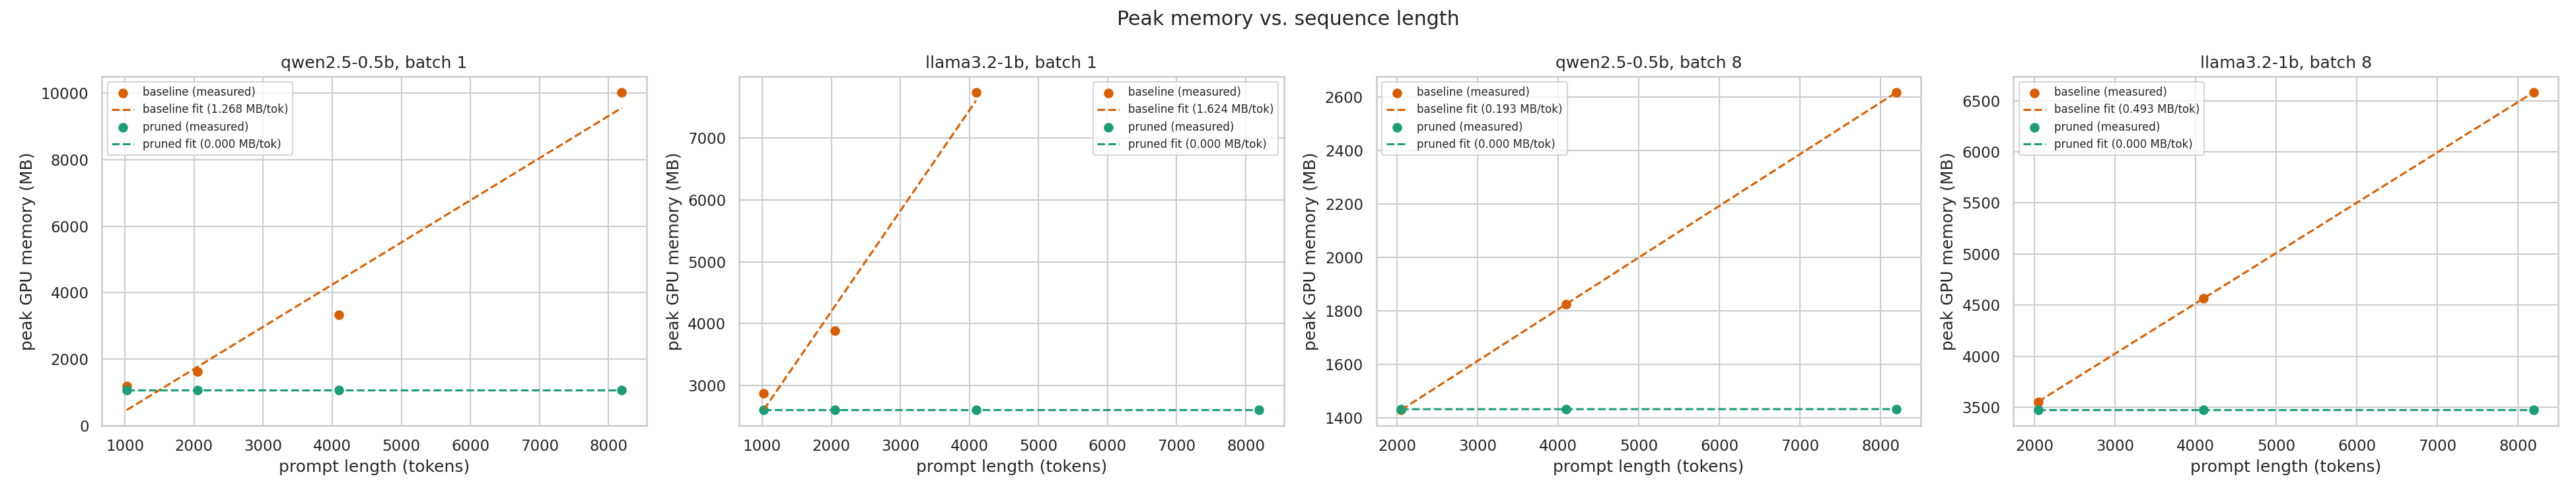

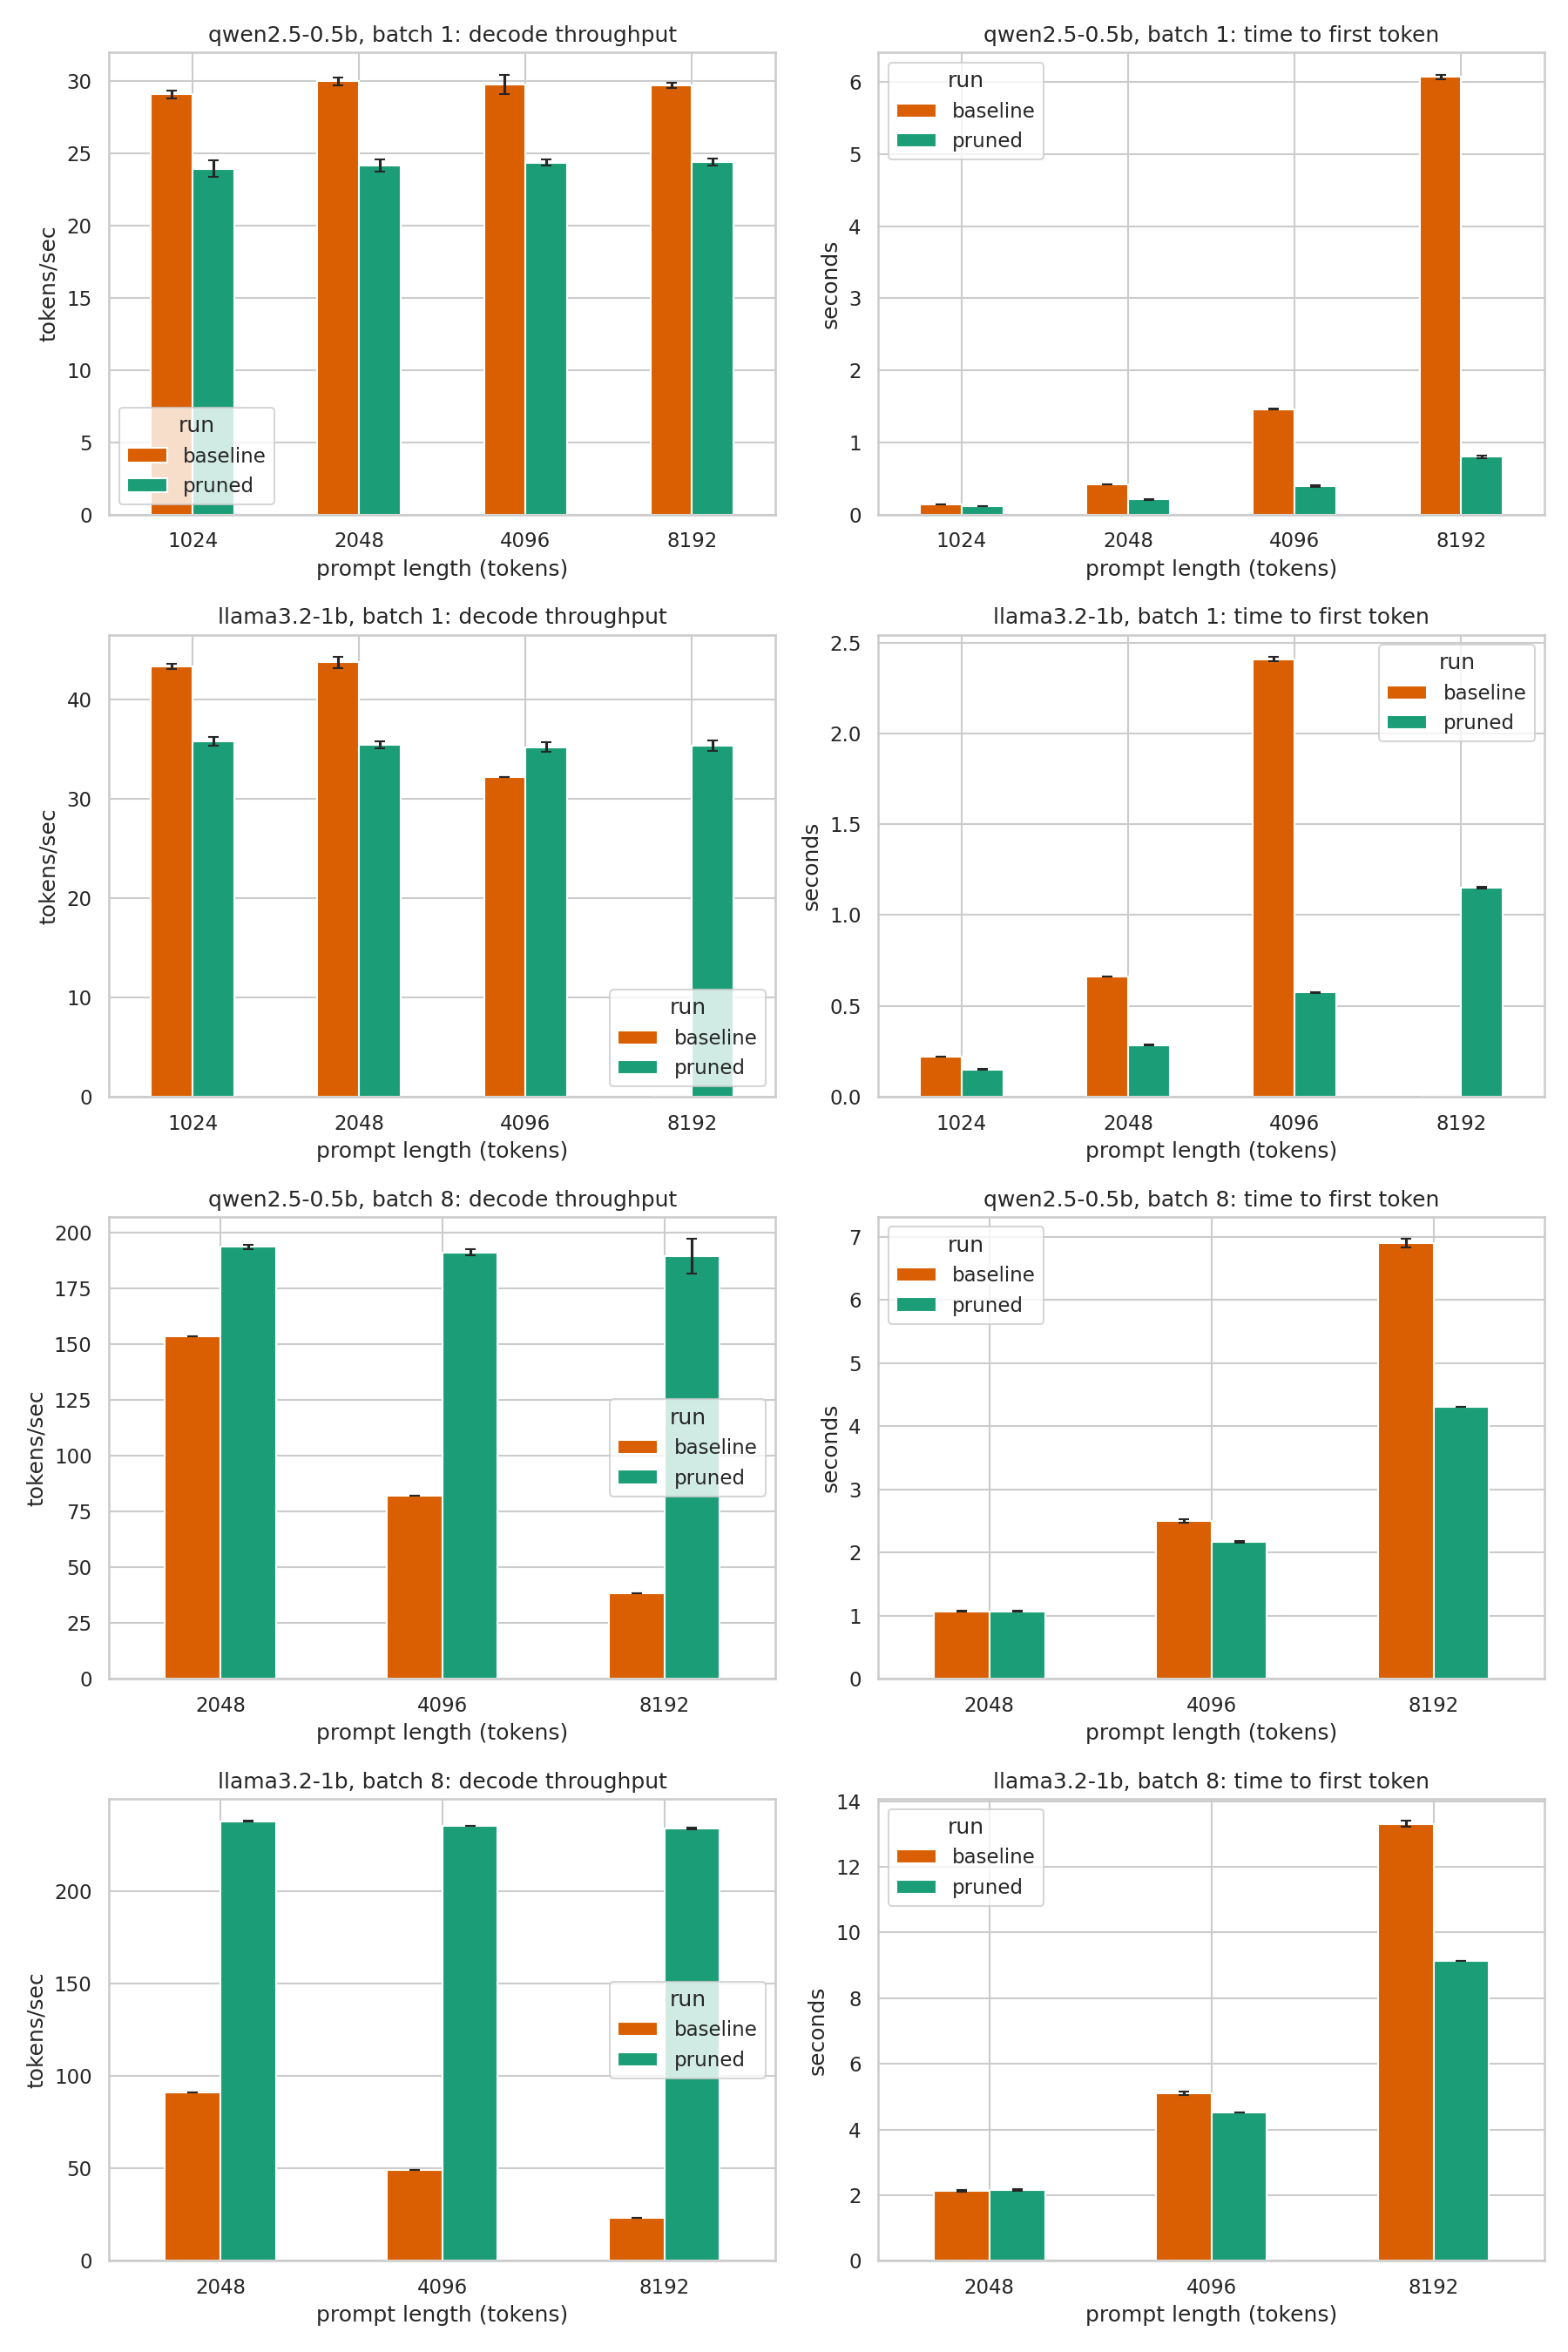

In [23]:
from IPython.display import Image, display
display(Image(f"results/{RUN}/figures/memory_scaling.png"))
display(Image(f"results/{RUN}/figures/throughput_comparison.png"))


## Bring the results back to the local repo

The CSVs are the only files needed locally: figures are rebuilt from it with
`python visualize.py --csv results/<RUN>/benchmark.csv --out-dir results/<RUN>/figures`.
Copy each printed CSV into the file of the same name under `results/<RUN>/` in the local repo.


In [24]:
!cat {OUT}


model,batch_size,seq_len,max_new_tokens,run,mode,prefill_chunk,window_size,pruning_active,obs_window,evict_slack,repeats,ttft_s,ttft_s_std,decode_time_s,decode_time_s_std,throughput_tok_s,throughput_tok_s_std,peak_mem_mb,peak_mem_mb_std,kv_cache_mb,kv_cache_mb_std,evictions,evictions_std
qwen2.5-0.5b,1,1024,128,baseline,none,0,,,,,3,0.13922688900000443,0.0032075127622722965,4.370761275666648,0.03922156327735768,29.058286970133576,0.2614185590368035,1179.067904,0.0,14.143488,0.0,0,0.0
qwen2.5-0.5b,1,1024,128,pruned,importance,512,512,True,32,32,3,0.11754841399999805,0.00414653105352415,5.311209005333315,0.1243831093114008,23.92042725744717,0.5594753822453873,1060.182528,0.0,6.63552,0.0,4,0.0
qwen2.5-0.5b,1,2048,128,baseline,none,0,,,,,3,0.41614711933334547,0.0012164141661599906,4.239218317666655,0.03938495929324621,29.960077830243666,0.278437821542149,1623.039488,0.0,26.7264,0.0,0,0.0
qwen2.5-0.5b,1,2048,128,pruned,importance,512,512,True,32,32,3,0.20697589666667682,0.009643907230339414

In [25]:
!cat results/{RUN}/ablation_sliding_window.csv


model,batch_size,seq_len,max_new_tokens,run,mode,prefill_chunk,window_size,pruning_active,obs_window,evict_slack,repeats,ttft_s,ttft_s_std,decode_time_s,decode_time_s_std,throughput_tok_s,throughput_tok_s_std,peak_mem_mb,peak_mem_mb_std,kv_cache_mb,kv_cache_mb_std,evictions,evictions_std,status
llama3.2-1b,8,2048,128,baseline,none,512,,,,,3,2.100535573333218,0.0252693717027091,11.143208317666753,0.0012236438322073833,91.17661441874215,0.010012253868837842,3555.060736,0.0,570.1632,0.0,0,0.0,ok
llama3.2-1b,8,2048,128,pruned,sliding_window,512,512,True,32,32,3,2.0533045880000222,0.011419178040265087,4.109571122333212,0.002763637808073151,247.22781916252197,0.16623075715629168,3439.863296,0.0,141.55776,0.0,6,0.0,ok
llama3.2-1b,8,4096,128,baseline,none,512,,,,,3,5.017943151999892,0.08679468052528012,20.69737923933326,0.023916778453381263,49.08838421247342,0.05671490331891115,4563.987456,0.0,1107.034112,0.0,0,0.0,ok
llama3.2-1b,8,4096,128,pruned,sliding_window,512,512,True,32,32,3,4.29585260

In [26]:
!cat results/{RUN}/ablation_chunked_baseline.csv


model,batch_size,seq_len,max_new_tokens,run,mode,prefill_chunk,window_size,pruning_active,obs_window,evict_slack,repeats,ttft_s,ttft_s_std,decode_time_s,decode_time_s_std,throughput_tok_s,throughput_tok_s_std,peak_mem_mb,peak_mem_mb_std,kv_cache_mb,kv_cache_mb_std,evictions,evictions_std,status
llama3.2-1b,1,1024,128,baseline,none,512,,,,,3,0.15869508100013263,0.000590363516210794,2.8089104936666445,0.03961854115724939,45.219213924355024,0.6332119480490181,2601.944576,0.0,37.715968,0.0,0,0.0,ok
llama3.2-1b,1,1024,128,pruned,importance,512,512,True,32,32,3,0.16540961866667203,0.003135443827082943,3.4894138069998917,0.028948230065444735,36.39746471406633,0.3013639435247968,2606.007808,0.0,17.69472,0.0,4,0.0,ok
llama3.2-1b,1,2048,128,baseline,none,512,,,,,3,0.3236054153333801,0.0014103708323566148,2.8492916079999304,0.022493973653808296,44.574327243936715,0.3505314266991504,2617.442816,0.0,71.2704,0.0,0,0.0,ok
llama3.2-1b,1,2048,128,pruned,importance,512,512,True,32,32,3,0.319356495000192

In [27]:
!cat results/{RUN}/quality.csv


model,context,eval_tokens,window_size,ppl_baseline,ppl_importance,ppl_sliding_window
qwen2.5-0.5b,2048,256,512,12.1578,12.8412,12.7255
qwen2.5-0.5b,4096,256,512,19.9092,22.5694,23.8259
llama3.2-1b,2048,256,512,12.2467,13.3979,12.9779
llama3.2-1b,4096,256,512,22.2343,23.7124,23.3492
